# 04 · Cosmic-ray (spike) removal

`despike` finds narrow spikes and replaces them; every spike is printed and kept in `history`. Three methods:

- `single` (default): each spectrum on its own; tells spikes from real bands by shape
- `compare`: compares each spectrum with the median of the others (repeated measurements only)
- `kalkan`: your MATLAB `spikeRemoval.m`, ported, for comparison

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import spectrum_toolkit as stk

cv = stk.load('../data/CV10-4M.xlsx', verbose=False)

## 1. Find and remove spikes

In [2]:
clean = cv.despike()          # default: method='single'

despike (single): 3 spike(s) in 2 of 14 spectra.
  - Spectrum 4: 1634.63-1636.8 (-2725), 1696.18-1701.56 (-9028)
  - Spectrum 11: 313.299-314.611 (-1849)


## 2. Before and after, all three methods

Grey: the other CV spectra. Red: original. Blue: after despike.

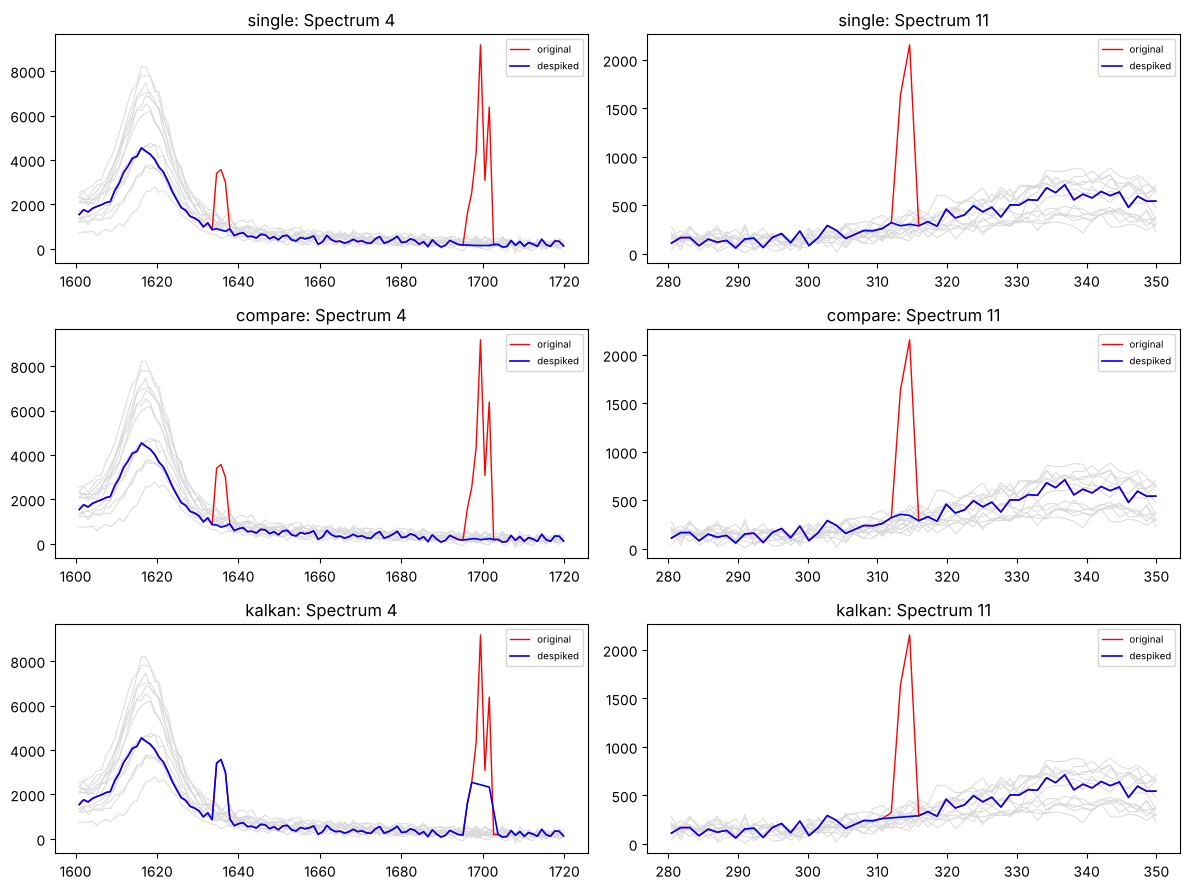

In [3]:
def zoom(before, after, i, lo, hi, ax, title):
    m = (before.x > lo) & (before.x < hi)
    for j in range(len(before)):
        if j != i:
            ax.plot(before.x[m], before.Y[j, m], color='0.85', lw=0.7)
    ax.plot(before.x[m], before.Y[i, m], 'r', lw=1, label='original')
    ax.plot(after.x[m], after.Y[i, m], 'b', lw=1.2, label='despiked')
    ax.set_title(title); ax.legend(fontsize=7)

results = {m: cv.despike(m, verbose=False) for m in ['single', 'compare', 'kalkan']}
fig, axes = plt.subplots(3, 2, figsize=(12, 9))
for r, (m, after) in enumerate(results.items()):
    zoom(cv, after, 3, 1600, 1720, axes[r, 0], f'{m}: Spectrum 4')
    zoom(cv, after, 10, 280, 350, axes[r, 1], f'{m}: Spectrum 11')
plt.tight_layout(); plt.show()

## 3. What each method changed

`kalkan` also changes many points that are only noise, and always the last points of each spectrum.

In [4]:
for m, after in results.items():
    n = sum(len(v) for v in after.history[-1]['spikes'].values())
    print(f'{m:8s}: {n} places changed')

single  : 3 places changed
compare : 3 places changed
kalkan  : 50 places changed


## 4. Settings to play with

- `threshold` (default 8): lower = more sensitive
- `width` (default 3): widest spike in points; real bands must be wider
- `sharpness` (default 1.0): how sharp for its height a spike must be
- `grow` (default 3): neighbours above this many noise units join the spike
- `passes` (default 2)

For `kalkan`: `window`, `nstd`, `ndata`, `nbins`, `passes` (same as in MATLAB).

In [5]:
sensitive = cv.despike(threshold=5)
strict = cv.despike(threshold=12)

despike (single): 5 spike(s) in 4 of 14 spectra.
  - Spectrum 3: 1790.08 (-366.9)
  - Spectrum 4: 1634.63-1636.8 (-2725), 1696.18-1701.56 (-9028)
  - Spectrum 11: 313.299-314.611 (-1849)
  - Spectrum 13: 1780.54 (-423.3)
despike (single): 3 spike(s) in 2 of 14 spectra.
  - Spectrum 4: 1634.63-1636.8 (-2725), 1696.18-1701.56 (-9028)
  - Spectrum 11: 313.299-314.611 (-1849)


## 5. Your other files

In [6]:
for f in ['RhB10-4M.xlsx', 'MB 10-4M.xlsx', 'CV+RhB+MB.xlsx', 'wt_raw.mat']:
    data = stk.load('../data/' + f, verbose=False)
    if isinstance(data, list):
        data = stk.combine(data, verbose=False)
    print(f); data.despike()

RhB10-4M.xlsx
despike (single): 0 spike(s) in 0 of 11 spectra.


MB 10-4M.xlsx
despike (single): 0 spike(s) in 0 of 5 spectra.


CV+RhB+MB.xlsx
despike (single): 1 spike(s) in 1 of 35 spectra.
  - Spectrum 25: 1025.52-1028.24 (-942.1)


wt_raw.mat


despike (single): 0 spike(s) in 0 of 550 spectra.
